In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

CANDIDATES = [os.environ.get("PALLAS_PACK"),
              os.path.join("data", "pallas_hackathon_data"),
              os.path.join("..", "pallas_hackathon_data"),
              "pallas_hackathon_data",
              os.path.join("data", "sample")]
PACK = None
for candidate in CANDIDATES:                 # the first folder that holds the pack wins
    if candidate and os.path.exists(os.path.join(candidate, "campaign_A.parquet")):
        PACK = candidate
        break
if PACK is None:
    raise SystemExit("no data pack found -- see data/README.md for the download "
                     "and unpack it as data/pallas_hackathon_data/")

# An old or partial download stops here, not three cells later with a KeyError:
# every file and column listed in the schema must be in the pack.
with open(os.path.join("data", "ontologies", "pack_schema.json"), encoding="utf-8") as fh:
    SCHEMA = json.load(fh)
for name, spec in SCHEMA["files"].items():
    path = os.path.join(PACK, name)
    if not os.path.exists(path):
        raise SystemExit(f"{path} is missing: {PACK} is not the current pack (data/README.md)")
    if name.endswith(".parquet"):
        absent = set(spec["columns"]) - set(pq.ParquetFile(path).schema_arrow.names)
        if absent:
            raise SystemExit(f"{name} lacks {sorted(absent)}: {PACK} is not the current pack")
if PACK == os.path.join("data", "sample"):
    print("using the 10 % SAMPLE in data/sample/ -- every number below will differ from "
          "the full pack's; download the full pack before training anything (data/README.md)")

# The scalar columns only; the spectra and density curves are most of the file size.
SCALARS = ["scan", "config", "p_1", "a_0", "c_N2", "x_of",
           "P_max", "cN2_max", "L_inj", "dip_frac",
           "E_med_MeV", "E_mean_MeV", "dE_mad", "dE_std", "q_pC", "q_end", "i_peak",
           "sigma_z", "sigma_y", "n_emit_x", "n_emit_y", "div_rms", "injected"]


def load(name):
    cols = pq.ParquetFile(f"{PACK}/{name}.parquet").schema.names
    return pd.read_parquet(f"{PACK}/{name}.parquet", columns=[c for c in SCALARS if c in cols])


A = load("campaign_A")
B = load("campaign_B")
grid = np.load(f"{PACK}/common_energy_grid_MeV.npy")   # shared energy axis, MeV
print(f"campaign A: {len(A):,} simulations   campaign B: {len(B):,} simulations")

campaign A: 13,073 simulations   campaign B: 5,286 simulations


In [2]:
for name in sorted(os.listdir(PACK)):
    if name.endswith(".parquet"):
        f = pq.ParquetFile(f"{PACK}/{name}")
        print(f"{name:34s} {f.metadata.num_rows:>9,} rows x {len(f.schema_arrow.names):>3} columns")

campaign_A.parquet                    13,073 rows x  35 columns
campaign_B.parquet                     5,286 rows x  35 columns
campaign_B_moments.parquet           211,360 rows x  57 columns
campaign_B_trajectories.parquet      322,615 rows x  13 columns
test_direct.parquet                      357 rows x   6 columns
test_inverse.parquet                   1,915 rows x  10 columns
test_inverse_B.parquet                   357 rows x  10 columns
test_moments_planes.parquet            3,213 rows x   7 columns
test_trajectory.parquet               40,341 rows x   7 columns
test_trajectory_ood.parquet           15,368 rows x   7 columns


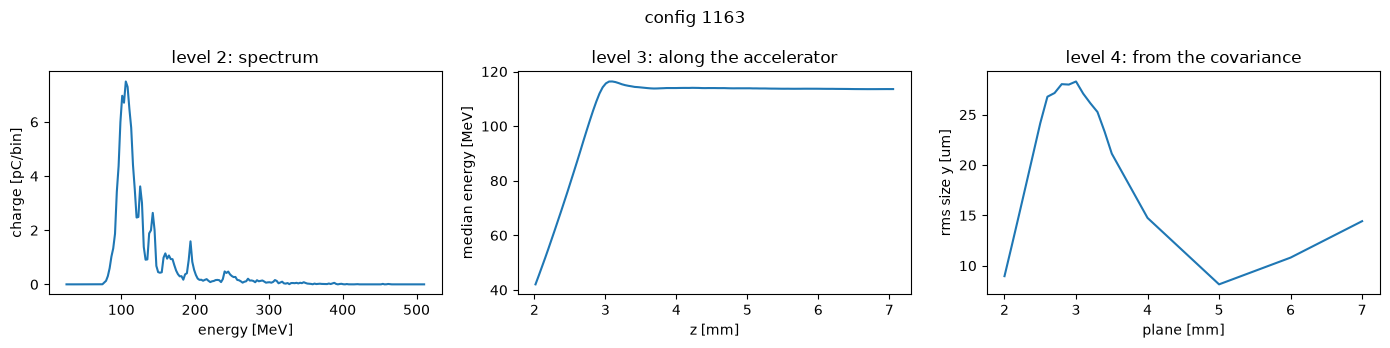

In [3]:
cfg = int(B.config[B.injected].iloc[0])      # one simulation that produced a bunch

row = pd.read_parquet(f"{PACK}/campaign_B.parquet",
                      columns=["config", "ener_axis_MeV", "spec_common"]).query("config == @cfg").iloc[0]
spectrum = row.spec_common                                          # pC per bin
traj = pd.read_parquet(f"{PACK}/campaign_B_trajectories.parquet").query("config == @cfg").sort_values("z_mm")
mom = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
mom = mom[(mom.sim_id == f"Config_{cfg}") & (mom.group == "all")].sort_values("plane_mm")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(grid, spectrum); ax[0].set(xlabel="energy [MeV]", ylabel="charge [pC/bin]", title="level 2: spectrum")
ax[1].plot(traj.z_mm, traj.E_MeV); ax[1].set(xlabel="z [mm]", ylabel="median energy [MeV]", title="level 3: along the accelerator")
ax[2].plot(mom.plane_mm, np.sqrt(mom.cov_11)); ax[2].set(xlabel="plane [mm]", ylabel="rms size y [um]", title="level 4: from the covariance")
fig.suptitle(f"config {cfg}"); plt.tight_layout(); plt.show()

In [4]:
B.loc[B.injected, ["E_med_MeV", "dE_mad", "q_pC", "i_peak", "sigma_z", "n_emit_x", "div_rms"]].describe().T[["min", "50%", "max"]]

,min,50%,max
E_med_MeV,6.697303e+01,1.339602e+02,241.277909
dE_mad,1.902867e-02,7.511952e-02,0.508474
q_pC,3.037840e+00,6.846694e+01,300.610191
i_peak,1.878321e+02,3.969007e+03,10000.958500
sigma_z,8.179158e-07,2.130239e-06,0.000008
n_emit_x,1.809471e-07,5.277838e-07,0.000009
div_rms,2.839408e-04,5.536467e-04,0.003879


## Baseline model



In [5]:
import sys

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, ".")
from pallas_score import normalised_to_physical, score_submission, physical_to_normalised

TARGETS = ["p_1", "a_0", "c_N2"]
FEATURES = ["E_med_MeV", "dE_mad", "q_end", "i_peak", "n_emit_x", "sigma_z", "sigma_y",
            "div_rms", "x_of"]
LOG_COLUMNS = ["q_end", "i_peak", "n_emit_x", "sigma_y"]   # these span several decades


def inputs_with_logs(frame):
    """The model's input table: FEATURES, with LOG_COLUMNS on log10 (all > 0 on injected rows)."""
    features = frame[FEATURES].copy()
    for col in LOG_COLUMNS:
        features[col] = np.log10(features[col])
    return features.to_numpy()

In [6]:
inj_a = A[(A.scan == "random") & A.injected].dropna(subset=FEATURES + TARGETS)
train, test = train_test_split(inj_a, test_size=0.2, random_state=0)
model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(inputs_with_logs(train), train[TARGETS])

# a linear model can leave the range it was trained on (a negative c_N2, say): keep it inside
TRAIN_MIN = train[TARGETS].min().to_numpy()
TRAIN_MAX = train[TARGETS].max().to_numpy()


def predict_clipped(frame):
    return np.clip(model.predict(inputs_with_logs(frame)), TRAIN_MIN, TRAIN_MAX)


print(f"trained on {len(train):,} simulations, holding out {len(test):,}")

trained on 5,766 simulations, holding out 1,442


In [7]:
holdout_pred_inverse = pd.DataFrame(predict_clipped(test), columns=TARGETS)
holdout_pred_inverse.insert(0, "config", test.config.to_numpy())
holdout_truth_inverse = test[["config"] + TARGETS]
holdout_scores_inverse = score_submission(holdout_pred_inverse, holdout_truth_inverse)
holdout_scores_inverse

{'p_1': 0.861095577373997,
 'a_0': 0.3892151510882682,
 'c_N2': 0.8195237028125559,
 'mean': 0.6899448104249405,
 'n_rows': 1442}

In [8]:
test_inputs_inverse = pd.read_parquet(f"{PACK}/test_inverse.parquet")
submission = pd.DataFrame(predict_clipped(test_inputs_inverse), columns=TARGETS)
submission.insert(0, "config", test_inputs_inverse.config.to_numpy())
submission.to_csv("submission_inverse.csv", index=False)
print(f"wrote submission_inverse.csv ({len(submission):,} rows)")

wrote submission_inverse.csv (1,915 rows)


In [9]:
OUR_ENSEMBLE = {"p_1": 0.9563, "a_0": 0.8264, "c_N2": 0.9473}   # in review
CEILING = {"p_1": 0.9940, "a_0": 0.9858, "c_N2": 0.9928}
pd.DataFrame({"linear baseline": {t: holdout_scores_inverse[t] for t in TARGETS},
              "our ensemble (in review)": OUR_ENSEMBLE,
              "ceiling": CEILING}).T.round(3)

,p_1,a_0,c_N2
linear baseline,0.861,0.389,0.820
our ensemble (in review),0.956,0.826,0.947
ceiling,0.994,0.986,0.993


In [10]:
DIRECT_INPUTS = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of"]
DIRECT_TARGETS = ["E_med_MeV", "dE_mad", "q_end"]


def targets_to_normalised(frame, targets):
    """The targets as the scorer sees them: log10 for charge and spread, energy unchanged. Fit on these."""
    return np.column_stack([physical_to_normalised(t, frame[t]) for t in targets])


def predictions_to_physical(pred, targets):
    """Model output back to physical units, the units a submission is written in."""
    return pd.DataFrame({t: normalised_to_physical(t, pred[:, i]) for i, t in enumerate(targets)})


b_train, b_test = train_test_split(B[B.injected], test_size=0.2, random_state=0)
direct = make_pipeline(StandardScaler(), LinearRegression())
direct.fit(b_train[DIRECT_INPUTS], targets_to_normalised(b_train, DIRECT_TARGETS))
print(f"trained on {len(b_train):,} simulations, holding out {len(b_test):,}")

trained on 2,305 simulations, holding out 577


In [11]:
holdout_pred_direct = predictions_to_physical(direct.predict(b_test[DIRECT_INPUTS]), DIRECT_TARGETS)
holdout_pred_direct.insert(0, "config", b_test.config.to_numpy())
holdout_scores_direct = score_submission(holdout_pred_direct, b_test[["config"] + DIRECT_TARGETS])

test_inputs_direct = pd.read_parquet(f"{PACK}/test_direct.parquet")
submission_direct = predictions_to_physical(direct.predict(test_inputs_direct[DIRECT_INPUTS]), DIRECT_TARGETS)
submission_direct.insert(0, "config", test_inputs_direct.config.to_numpy())
submission_direct.to_csv("submission_direct.csv", index=False)
print(f"wrote submission_direct.csv ({len(submission_direct):,} rows)")

wrote submission_direct.csv (357 rows)


In [12]:
OUR_DIRECT_MODEL = {"E_med_MeV": 0.9744, "dE_mad": 0.8036, "q_end": 0.9420}   # internal
pd.DataFrame({"linear baseline": {t: holdout_scores_direct[t] for t in DIRECT_TARGETS},
              "our internal model": OUR_DIRECT_MODEL}).T.round(3)

,E_med_MeV,dE_mad,q_end
linear baseline,0.940,0.261,0.814
our internal model,0.974,0.804,0.942


## The trajectory task 

In [13]:
TRAJECTORY_TARGETS = ["E_MeV", "q_pC", "dE_pct", "emit_um", "div_mrad", "sigz_um"]

test_inputs_trajectory = pd.read_parquet(f"{PACK}/test_trajectory.parquet")
print("the test file gives you:", ", ".join(test_inputs_trajectory.columns))

# the file you hand in: these two key columns, then one column per target
submission_trajectory = test_inputs_trajectory[["config", "z_mm"]].copy()
for target in TRAJECTORY_TARGETS:
    submission_trajectory[target] = np.nan          # replace with your model's predictions
print(f"{len(submission_trajectory):,} rows to fill -> submission_trajectory.csv")
submission_trajectory.head()

the test file gives you: config, z_mm, P_max, cN2_max, L_inj, dip_frac, x_of
40,341 rows to fill -> submission_trajectory.csv


,config,z_mm,E_MeV,q_pC,dE_pct,emit_um,div_mrad,sigz_um
0,1002,2.015055,NaN,NaN,NaN,NaN,NaN,NaN
1,1002,2.060053,NaN,NaN,NaN,NaN,NaN,NaN
2,1002,2.105055,NaN,NaN,NaN,NaN,NaN,NaN
3,1002,2.150053,NaN,NaN,NaN,NaN,NaN,NaN
4,1002,2.195155,NaN,NaN,NaN,NaN,NaN,NaN


## PyTorch MLP models


In [18]:
import random

import numpy as np
import torch
from torch import nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

MLP_HIDDEN = (1024, 512, 256)
MLP_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class _MLP(nn.Module):
    def __init__(self, n_in, n_out, hidden):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def _group_split(groups, test_size=0.15, random_state=0):
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    return next(splitter.split(np.zeros(len(groups)), groups=groups))


def fit_mlp(X, y, groups, hidden=MLP_HIDDEN, epochs=300, batch_size=256,
            learning_rate=1e-3, patience=30, random_state=0):
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)

    # split fit / validation par groupe (config), pour l'early stopping
    fit_idx, val_idx = _group_split(np.asarray(groups), random_state=random_state)

    x_scaler, y_scaler = StandardScaler().fit(X[fit_idx]), StandardScaler().fit(y[fit_idx])
    x_fit = torch.tensor(x_scaler.transform(X[fit_idx]), dtype=torch.float32)
    y_fit = torch.tensor(y_scaler.transform(y[fit_idx]), dtype=torch.float32)
    x_val = torch.tensor(x_scaler.transform(X[val_idx]), dtype=torch.float32, device=MLP_DEVICE)
    y_val = torch.tensor(y_scaler.transform(y[val_idx]), dtype=torch.float32, device=MLP_DEVICE)

    torch.manual_seed(random_state); np.random.seed(random_state); random.seed(random_state)
    net = _MLP(X.shape[1], y.shape[1], hidden).to(MLP_DEVICE)
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    loss_fn = nn.MSELoss()

    best_state, best_loss, wait = None, float("inf"), 0
    history = {"train_loss": [], "val_loss": [], "best_epoch": 0}     # <-- ajout

    for epoch in range(epochs):
        net.train()
        order = torch.randperm(len(x_fit))
        epoch_losses = []                                             # <-- ajout
        for start in range(0, len(order), batch_size):
            ix = order[start:start + batch_size]
            pred = net(x_fit[ix].to(MLP_DEVICE))
            loss = loss_fn(pred, y_fit[ix].to(MLP_DEVICE))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            epoch_losses.append(loss.item())                          # <-- ajout
        net.eval()
        with torch.no_grad():
            val_loss = float(loss_fn(net(x_val), y_val).cpu())
        history["train_loss"].append(float(np.mean(epoch_losses)))    # <-- ajout
        history["val_loss"].append(val_loss)                          # <-- ajout
        if val_loss < best_loss - 1e-7:
            best_loss, wait = val_loss, 0
            history["best_epoch"] = epoch                             # <-- ajout
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    if best_state is not None: net.load_state_dict(best_state)
    return {"model": net.eval(), "x_scaler": x_scaler, "y_scaler": y_scaler,
            "epochs": epoch + 1, "device": str(MLP_DEVICE), "best_val_mse": best_loss,
            "history": history}                                       # <-- ajout


def predict_mlp(fit, X):
    X = torch.tensor(fit["x_scaler"].transform(np.asarray(X)), dtype=torch.float32, device=MLP_DEVICE)
    with torch.no_grad():
        pred = fit["model"](X).cpu().numpy()
    return fit["y_scaler"].inverse_transform(pred)


print(f"PyTorch {torch.__version__}; device={MLP_DEVICE}; default hidden={MLP_HIDDEN}")

PyTorch 2.14.1+cpu; device=cpu; default hidden=(1024, 512, 256)


### Inverse A: linear versus MLP

In [15]:
# Compare on the existing inverse holdout, then fit the MLP on all eligible rows for the hidden test.
mlp_inverse_holdout = fit_mlp(inputs_with_logs(train), train[TARGETS].to_numpy(), train.config.to_numpy())
mlp_pred_inverse = np.clip(predict_mlp(mlp_inverse_holdout, inputs_with_logs(test)), TRAIN_MIN, TRAIN_MAX)
mlp_holdout_pred_inverse = pd.DataFrame(mlp_pred_inverse, columns=TARGETS)
mlp_holdout_pred_inverse.insert(0, "config", test.config.to_numpy())
mlp_holdout_scores_inverse = score_submission(mlp_holdout_pred_inverse, holdout_truth_inverse)
comparison_inverse = pd.DataFrame({
    "linear baseline": {t: holdout_scores_inverse[t] for t in TARGETS},
    "PyTorch MLP": {t: mlp_holdout_scores_inverse[t] for t in TARGETS},
})
comparison_inverse.loc["mean"] = [holdout_scores_inverse["mean"], mlp_holdout_scores_inverse["mean"]]
print(comparison_inverse.round(4))

mlp_inverse_full = fit_mlp(inputs_with_logs(inj_a), inj_a[TARGETS].to_numpy(), inj_a.config.to_numpy())
mlp_inverse_test = pd.DataFrame(np.clip(predict_mlp(mlp_inverse_full, inputs_with_logs(test_inputs_inverse)),
                                         inj_a[TARGETS].min().to_numpy(), inj_a[TARGETS].max().to_numpy()), columns=TARGETS)
mlp_inverse_test.insert(0, "config", test_inputs_inverse.config.to_numpy())
mlp_inverse_test.to_csv("submission_inverse_mlp.csv", index=False)
print(f"wrote submission_inverse_mlp.csv ({len(mlp_inverse_test):,} rows)")


      linear baseline  PyTorch MLP
p_1            0.8611       0.9905
a_0            0.3892       0.9675
c_N2           0.8195       0.9893
mean           0.6899       0.9824
wrote submission_inverse_mlp.csv (1,915 rows)


### Direct B: linear versus MLP

In [16]:
mlp_direct_holdout = fit_mlp(b_train[DIRECT_INPUTS].to_numpy(),
                              targets_to_normalised(b_train, DIRECT_TARGETS),
                              b_train.config.to_numpy())
mlp_direct_norm = predict_mlp(mlp_direct_holdout, b_test[DIRECT_INPUTS])
mlp_pred_direct = predictions_to_physical(mlp_direct_norm, DIRECT_TARGETS)
mlp_pred_direct.insert(0, "config", b_test.config.to_numpy())
mlp_scores_direct = score_submission(mlp_pred_direct, b_test[["config"] + DIRECT_TARGETS])
comparison_direct = pd.DataFrame({
    "linear baseline": {t: holdout_scores_direct[t] for t in DIRECT_TARGETS},
    "PyTorch MLP": {t: mlp_scores_direct[t] for t in DIRECT_TARGETS},
})
comparison_direct.loc["mean"] = [holdout_scores_direct["mean"], mlp_scores_direct["mean"]]
print(comparison_direct.round(4))

mlp_direct_full = fit_mlp(B[B.injected][DIRECT_INPUTS].to_numpy(),
                          targets_to_normalised(B[B.injected], DIRECT_TARGETS),
                          B[B.injected].config.to_numpy())
mlp_direct_test = predictions_to_physical(predict_mlp(mlp_direct_full, test_inputs_direct[DIRECT_INPUTS]), DIRECT_TARGETS)
mlp_direct_test.insert(0, "config", test_inputs_direct.config.to_numpy())
mlp_direct_test.to_csv("submission_direct_mlp.csv", index=False)
print(f"wrote submission_direct_mlp.csv ({len(mlp_direct_test):,} rows)")


           linear baseline  PyTorch MLP
E_med_MeV           0.9399       0.9964
dE_mad              0.2614       0.9817
q_end               0.8138       0.9988
mean                0.6717       0.9923
wrote submission_direct_mlp.csv (357 rows)


### Trajectory B: config-held-out MLP

In [ ]:
TRAJECTORY_INPUTS = ["z_mm", "P_max", "cN2_max", "L_inj", "dip_frac", "x_of"]
trajectory = pd.read_parquet(f"{PACK}/campaign_B_trajectories.parquet")
trajectory = trajectory.dropna(subset=TRAJECTORY_INPUTS + TRAJECTORY_TARGETS)
traj_fit_idx, traj_hold_idx = _group_split(trajectory.config.to_numpy(), random_state=0)
traj_train, traj_test = trajectory.iloc[traj_fit_idx], trajectory.iloc[traj_hold_idx]
traj_truth_holdout = traj_test[["config", "z_mm", "L_inj"] + TRAJECTORY_TARGETS]
# A trajectory linear baseline on the same config-held-out split.
traj_linear = make_pipeline(StandardScaler(), LinearRegression())
traj_linear.fit(traj_train[TRAJECTORY_INPUTS], physical_targets(traj_train, TRAJECTORY_TARGETS))
traj_linear_pred = predictions_to_physical(traj_linear.predict(traj_test[TRAJECTORY_INPUTS]), TRAJECTORY_TARGETS)
traj_linear_pred.insert(0, "z_mm", traj_test.z_mm.to_numpy())
traj_linear_pred.insert(0, "config", traj_test.config.to_numpy())
traj_scores_linear = score_submission(traj_linear_pred, traj_truth_holdout)

traj_mlp_holdout = fit_mlp(traj_train[TRAJECTORY_INPUTS].to_numpy(),
                            physical_targets(traj_train, TRAJECTORY_TARGETS),
                            traj_train.config.to_numpy())
traj_pred_holdout = predictions_to_physical(
    predict_mlp(traj_mlp_holdout, traj_test[TRAJECTORY_INPUTS]), TRAJECTORY_TARGETS)
traj_pred_holdout.insert(0, "z_mm", traj_test.z_mm.to_numpy())
traj_pred_holdout.insert(0, "config", traj_test.config.to_numpy())
traj_scores_mlp = score_submission(traj_pred_holdout, traj_truth_holdout)
comparison_trajectory = pd.DataFrame({
    "linear baseline": {t: traj_scores_linear[t] for t in TRAJECTORY_TARGETS},
    "PyTorch MLP": {t: traj_scores_mlp[t] for t in TRAJECTORY_TARGETS},
})
comparison_trajectory.loc["mean"] = [traj_scores_linear["mean"], traj_scores_mlp["mean"]]
print(comparison_trajectory.round(4))

# Refit using all known trajectories (with an internal group-aware early-stopping split).
traj_mlp_full = fit_mlp(trajectory[TRAJECTORY_INPUTS].to_numpy(),
                         physical_targets(trajectory, TRAJECTORY_TARGETS),
                         trajectory.config.to_numpy())
traj_pred_test = predictions_to_physical(
    predict_mlp(traj_mlp_full, test_inputs_trajectory[TRAJECTORY_INPUTS]), TRAJECTORY_TARGETS)
submission_trajectory = test_inputs_trajectory[["config", "z_mm"]].copy()
for target in TRAJECTORY_TARGETS:
    submission_trajectory[target] = traj_pred_test[target].to_numpy()
submission_trajectory.to_csv("submission_trajectory.csv", index=False)
print(f"wrote submission_trajectory.csv ({len(submission_trajectory):,} rows)")
submission_trajectory.head()


          linear baseline  PyTorch MLP
E_MeV             -0.3731       0.9968
q_pC               0.8234       0.9971
dE_pct             0.3703       0.9799
emit_um           -0.0168       0.9749
div_mrad           0.7075       0.9862
sigz_um            0.6312       0.9802
mean               0.3571       0.9858
wrote submission_trajectory.csv (40,341 rows)


KeyError: 'history'

In [ ]:
import matplotlib.pyplot as plt

def plot_learning_curve(fit, title="Courbe d'apprentissage"):
    h = fit["history"]
    epochs = np.arange(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(epochs, h["train_loss"], label="train (MSE)")
    ax.plot(epochs, h["val_loss"], label="validation (MSE)")
    ax.axvline(h["best_epoch"] + 1, color="gray", ls="--",
               label=f"meilleure epoch = {h['best_epoch'] + 1}")
    ax.set_yscale("log")                  # la loss varie sur plusieurs décades
    ax.set_xlabel("epoch"); ax.set_ylabel("MSE (espace normalisé)")
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
    plt.show()

plot_learning_curve(traj_mlp_holdout, "Trajectoire : MLP")